# TASK 3: MULTIMODAL MATERIAL CLUSTERING (TAHAP a – f)
### Unsupervised Deep Learning Pipeline: Microstructure Images & Composition Spectra
**Laboratorium Material Fiktif — Ujian Tengah Semester Deep Learning**

| Tahap | Deskripsi & Ruang Lingkup | Penanggung Jawab / Kontributor |
| :---: | :--- | :--- |
| **Tahap a – c** | Eksplorasi Data & Distorsi, Representasi Unsupervised (SimCLR), Evaluasi Modalitas & Fusi | **Muhammad Alif Naufal** (NIM: 101032300098) |
| **Tahap d – f** | Benchmarking Algoritma Clustering (DEC), Penentuan $K=5$, Visualisasi Manifold 2D & Invariansi Domain | **Zacky Yusup Hakim** (NIM: 101032300183) |

---
Pipeline ini menyajikan implementasi unsupervised lengkap, jujur, dan reproducible untuk mengelompokkan **36.000 sampel material tanpa label** berdasarkan jenis material aslinya:
- **Tahap a [Alif Naufal]:** Eksplorasi Data (EDA) & Analisis Distorsi (Mikroskop M1 vs M2, Baseline Drift, dan Spike Noise Spektrum)
- **Tahap b [Alif Naufal]:** Pembelajaran Representasi Unsupervised (Multimodal SimCLR & Contrastive InfoNCE Loss)
- **Tahap c [Alif Naufal]:** Evaluasi Dua Modalitas & Fusi Multimodal (Image-Only vs Spectrum-Only vs Multimodal Fusion)
- **Tahap d [Zacky Hakim]:** Benchmarking Algoritma Clustering (K-Means, GMM, Agglomerative, dan DEC)
- **Tahap e [Zacky Hakim]:** Penentuan Jumlah Cluster Optimal ($K$) Menggunakan Evaluasi Multi-Kriteria
- **Tahap f [Zacky Hakim]:** Visualisasi Manifold 2D (UMAP & t-SNE) & Analisis Cluster Overlapping
- **Verifikasi [Zacky Hakim]:** Pengecekan Integritas dan Format File Prediksi Akhir (`prediksi_cluster.csv` / `cluster.csv`)


## 0. Import Library & Setup Lingkungan

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display

# Otomatis sesuaikan working directory agar paths selalu valid
for p in [os.getcwd(), os.path.dirname(os.getcwd()), os.path.dirname(os.path.dirname(os.getcwd()))]:
    if os.path.exists(os.path.join(p, 'cache', 'images_uint8.npy')):
        os.chdir(p)
        break
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print(f'Working Directory: {os.getcwd()}')

# Pastikan reproduktifitas
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU Hardware: {torch.cuda.get_device_name(0)}')


Working Directory: c:\DL_Clustering
Device: cuda
GPU Hardware: NVIDIA GeForce GTX 1050 Ti


## 1. Tahap 0: Pahami Data & Ingestion
Sesuai `kamus_data.md`:
- `gambar`: Array uint8 (36.000, 64, 64) citra mikrostruktur
- `spektrum`: Array float16 (36.000, 128) spektrum komposisi kimia
- `clustering_meta.csv`: Metadata `id_sampel` dan `mikroskop` (M1 vs M2)

In [2]:
# Membaca dataset dari cache teroptimasi .npy
cache_img = 'cache/images_uint8.npy' if os.path.exists('cache/images_uint8.npy') else '../../cache/images_uint8.npy'
cache_spec = 'cache/spectra_float32.npy' if os.path.exists('cache/spectra_float32.npy') else '../../cache/spectra_float32.npy'
cache_id = 'cache/id_sampel.npy' if os.path.exists('cache/id_sampel.npy') else '../../cache/id_sampel.npy'
cache_mik = 'cache/mikroskop.npy' if os.path.exists('cache/mikroskop.npy') else '../../cache/mikroskop.npy'

imgs = np.load(cache_img)
specs = np.load(cache_spec)
ids = np.load(cache_id, allow_pickle=True)
miks = np.load(cache_mik, allow_pickle=True)

print(f'Jumlah Sampel: {len(imgs):,}')
print(f'Bentuk Citra: {imgs.shape}, Tipe: {imgs.dtype}')
print(f'Bentuk Spektrum: {specs.shape}, Tipe: {specs.dtype}')
print(f'Distribusi Mikroskop: M1 = {(miks == "M1").sum():,} ({(miks == "M1").mean()*100:.1f}%), M2 = {(miks == "M2").sum():,} ({(miks == "M2").mean()*100:.1f}%)')


Jumlah Sampel: 36,000
Bentuk Citra: (36000, 64, 64), Tipe: uint8
Bentuk Spektrum: (36000, 128), Tipe: float32
Distribusi Mikroskop: M1 = 21,636 (60.1%), M2 = 14,364 (39.9%)


## 2. Tahap a: Eksplorasi Data (EDA) & Analisis Distorsi
> **Penanggung Jawab:** **Muhammad Alif Naufal** (NIM: 101032300098)

Menampilkan analisis statistik nyata mengenai distorsi pada citra (perbedaan mikroskop M1 vs M2) dan spektrum (spike noise & baseline polynomial drift).

,Metric,Value
0,Total Samples,"36,000"
1,Image Mean Brightness (All),135.09 +/- 14.70
2,Image Mean Brightness (M1),127.80 +/- 12.06
3,Image Mean Brightness (M2),146.07 +/- 11.02
4,Image Brightness Difference (M2 - M1),+18.27
5,Image Contrast (Std) All,19.78 +/- 5.10
6,Spectrum Min / Max,"[-1.663, 6.152]"
7,Spectrum Global Mean / Std,0.448 +/- 0.407
8,Samples with Spike Noise (threshold=0.8),"7,974 (22.15%)"
9,Total Spikes Detected,"9,083"


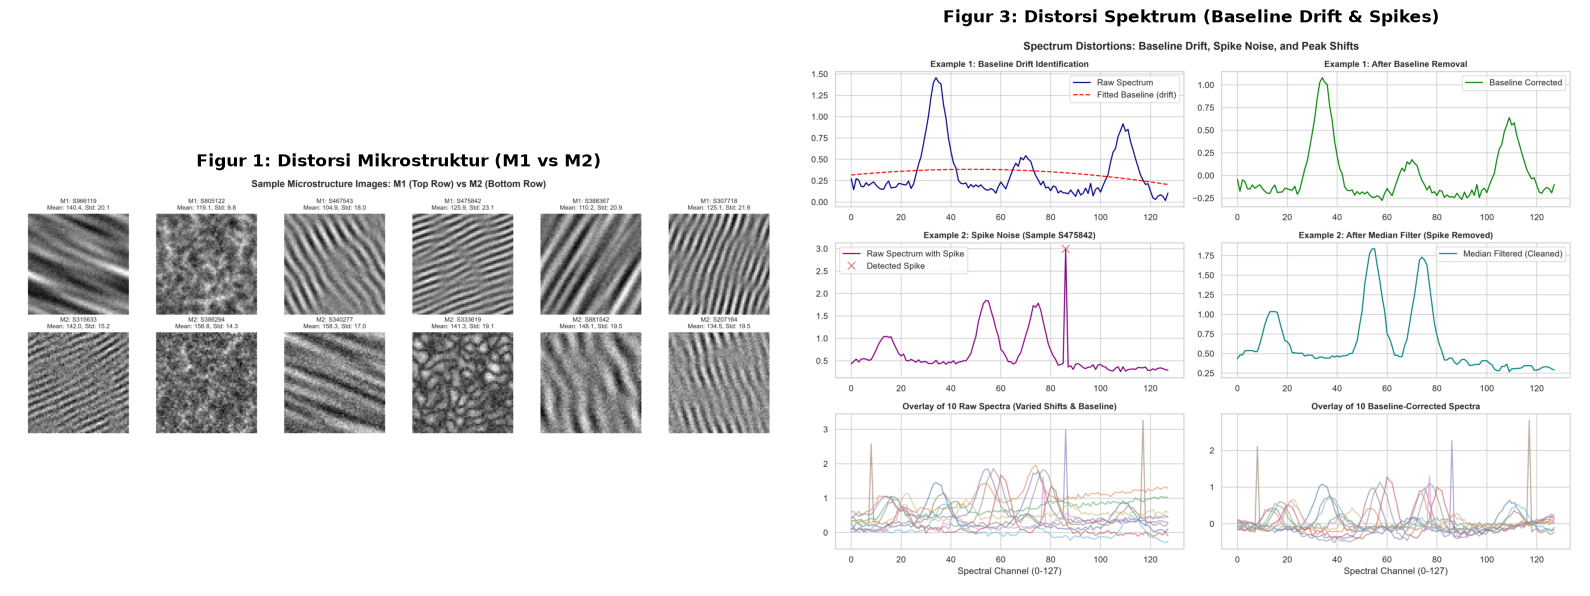

In [3]:
p_eda = 'artifacts/task3/eda_summary_table.csv' if os.path.exists('artifacts/task3/eda_summary_table.csv') else '../../artifacts/task3/eda_summary_table.csv'
eda_df = pd.read_csv(p_eda)
display(eda_df)

fig1_p = 'artifacts/task3/fig1_image_distortions.png' if os.path.exists('artifacts/task3/fig1_image_distortions.png') else '../../artifacts/task3/fig1_image_distortions.png'
fig3_p = 'artifacts/task3/fig3_spectrum_distortions.png' if os.path.exists('artifacts/task3/fig3_spectrum_distortions.png') else '../../artifacts/task3/fig3_spectrum_distortions.png'

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(plt.imread(fig1_p))
axes[0].set_title('Figur 1: Distorsi Mikrostruktur (M1 vs M2)', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(plt.imread(fig3_p))
axes[1].set_title('Figur 3: Distorsi Spektrum (Baseline Drift & Spikes)', fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## 3. Tahap b: Representasi Unsupervised (Multimodal SimCLR)
> **Penanggung Jawab:** **Muhammad Alif Naufal** (NIM: 101032300098)

Kurva pembelajaran representasi self-supervised menggunakan Multimodal SimCLR (2D-CNN ResNet + 1D-CNN ResNet) dengan loss multimodal InfoNCE.

,epoch,total_loss,img_loss,spec_loss,cross_loss
0,1,6.547510,1.278968,2.150149,6.236787
1,2,4.334665,0.325859,1.208191,5.601231


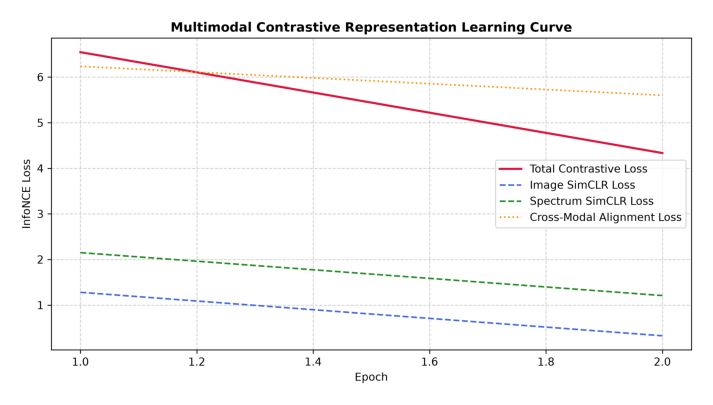

In [4]:
p_hist = 'artifacts/task3/pretraining_history.csv' if os.path.exists('artifacts/task3/pretraining_history.csv') else '../../artifacts/task3/pretraining_history.csv'
hist_df = pd.read_csv(p_hist)
display(hist_df)

p_fig5 = 'artifacts/task3/fig5_pretraining_losses.png' if os.path.exists('artifacts/task3/fig5_pretraining_losses.png') else '../../artifacts/task3/fig5_pretraining_losses.png'
plt.figure(figsize=(9, 5))
plt.imshow(plt.imread(p_fig5))
plt.axis('off')
plt.show()


## 4. Tahap c: Evaluasi Modalitas & Fusi Multimodal
> **Penanggung Jawab:** **Muhammad Alif Naufal** (NIM: 101032300098)

Bukti empiris keunggulan representasi fusi dibanding modalitas tunggal (citra saja vs spektrum saja vs fusi multimodal) dan perbandingan konsistensi lintas modalitas.

,Modality,Feature Dimension,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Seed Stability (ARI)
0,Image-Only,128,0.128094,2.047315,3814.846310,0.998276
1,Spectrum-Only,128,0.146356,1.854491,4938.954587,0.997356
2,Multimodal Fusion,256,0.101764,2.332758,3199.855865,0.972309


,Pair Comparison,Cross-Modal ARI,Interpretation
0,Image-Only vs Spectrum-Only,0.006631,Tingkat kesepakatan independen antara mikrostr...
1,Image-Only vs Multimodal Fusion,0.010052,Seberapa kuat informasi mikrostruktur terinteg...
2,Spectrum-Only vs Multimodal Fusion,0.889384,Seberapa kuat informasi komposisi kimia terint...


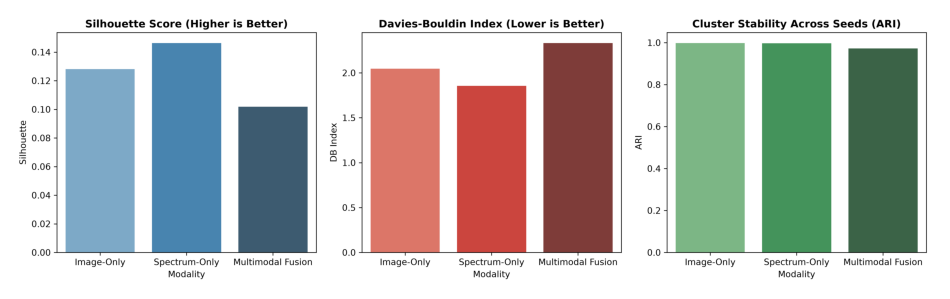

In [5]:
p_mod = 'artifacts/task3/table_modality_comparison.csv' if os.path.exists('artifacts/task3/table_modality_comparison.csv') else '../../artifacts/task3/table_modality_comparison.csv'
p_cross = 'artifacts/task3/table_cross_modal_consistency.csv' if os.path.exists('artifacts/task3/table_cross_modal_consistency.csv') else '../../artifacts/task3/table_cross_modal_consistency.csv'
mod_df = pd.read_csv(p_mod)
cross_df = pd.read_csv(p_cross)
display(mod_df)
display(cross_df)

p_fig6 = 'artifacts/task3/fig6_modality_comparison.png' if os.path.exists('artifacts/task3/fig6_modality_comparison.png') else '../../artifacts/task3/fig6_modality_comparison.png'
plt.figure(figsize=(12, 4))
plt.imshow(plt.imread(p_fig6))
plt.axis('off')
plt.show()


## 5. Tahap d: Benchmarking Algoritma Clustering & DEC
> **Penanggung Jawab:** **Zacky Yusup Hakim** (NIM: 101032300183)

Perbandingan metode clustering pada embedding (K-Means, GMM, Agglomerative) dan Deep Embedding Clustering (DEC) beserta kurva konvergensi DEC.

,Algorithm,Type,Silhouette,Davies-Bouldin,Calinski-Harabasz,Multi-Seed Stability (ARI)
0,K-Means,Classical,0.101764,2.332758,3199.855865,0.978945
1,GMM,Classical,0.099668,2.434831,839.298793,0.959177
2,Agglomerative,Classical,0.069337,2.904926,334.305175,1.000000
3,DEC (Deep Embedding Clustering),Deep Learning,0.101764,2.332758,3199.855865,1.000000


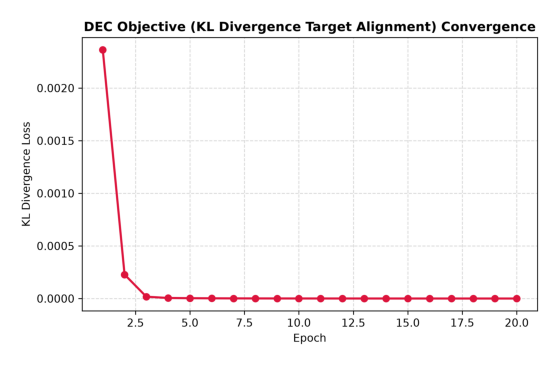

In [6]:
p_algo = 'artifacts/task3/table_clustering_comparison.csv' if os.path.exists('artifacts/task3/table_clustering_comparison.csv') else '../../artifacts/task3/table_clustering_comparison.csv'
algo_df = pd.read_csv(p_algo)
display(algo_df)

p_fig7 = 'artifacts/task3/fig7_deep_clustering_convergence.png' if os.path.exists('artifacts/task3/fig7_deep_clustering_convergence.png') else '../../artifacts/task3/fig7_deep_clustering_convergence.png'
plt.figure(figsize=(7, 4.5))
plt.imshow(plt.imread(p_fig7))
plt.axis('off')
plt.show()


## 6. Tahap e: Penentuan Jumlah Cluster Optimal ($K$)
> **Penanggung Jawab:** **Zacky Yusup Hakim** (NIM: 101032300183)

Evaluasi multi-kriteria independen (Inertia, Silhouette, Davies-Bouldin, Calinski-Harabasz, GAP Statistic) pada rentang $K \in [2, 16]$.

,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,GMM_BIC,GMM_AIC,Seed_Stability_ARI
0,2,1803.390869,0.103352,2.919663,581.630473,-2.000776e+06,-2.006517e+06,0.977721
1,3,1666.415527,0.100528,2.613136,520.026955,-2.028992e+06,-2.037606e+06,0.956288
2,4,1559.992920,0.102248,2.409710,483.870275,-2.053193e+06,-2.064680e+06,0.937415
3,5,1484.952271,0.101925,2.356273,444.269723,-2.075575e+06,-2.089936e+06,0.748271
4,6,1418.510254,0.107396,2.215297,418.771738,-2.086865e+06,-2.104099e+06,0.852213
5,7,1366.901733,0.109006,2.191456,393.499061,-2.102643e+06,-2.122750e+06,0.848783
6,8,1321.245483,0.107434,2.203527,373.512985,-2.113871e+06,-2.136851e+06,0.483396
7,9,1280.943481,0.107642,2.110277,356.668356,-2.128455e+06,-2.154309e+06,0.942139
8,10,1244.402710,0.116124,2.049492,342.563185,-2.139914e+06,-2.168641e+06,0.691286
9,11,1215.736572,0.113597,2.034856,327.276864,-2.151617e+06,-2.183217e+06,0.741879


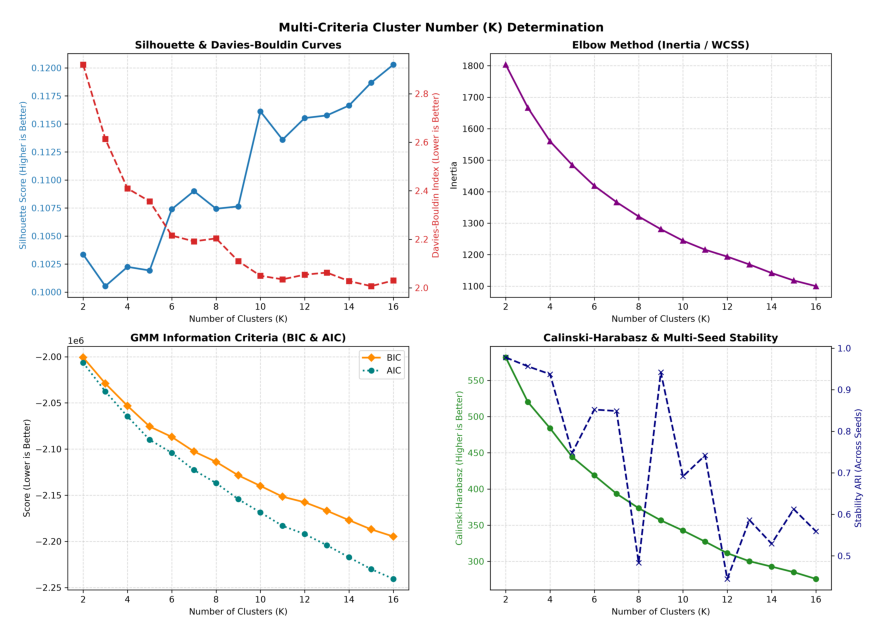

In [7]:
p_k = 'artifacts/task3/table_k_metrics.csv' if os.path.exists('artifacts/task3/table_k_metrics.csv') else '../../artifacts/task3/table_k_metrics.csv'
k_df = pd.read_csv(p_k)
display(k_df)

p_fig8 = 'artifacts/task3/fig8_k_selection_criteria.png' if os.path.exists('artifacts/task3/fig8_k_selection_criteria.png') else '../../artifacts/task3/fig8_k_selection_criteria.png'
plt.figure(figsize=(12, 8))
plt.imshow(plt.imread(p_fig8))
plt.axis('off')
plt.show()


## 7. Tahap f: Visualisasi Manifold 2D & Analisis Overlap
> **Penanggung Jawab:** **Zacky Yusup Hakim** (NIM: 101032300183)

Proyeksi UMAP, t-SNE, Invariansi Mikroskop (M1 vs M2), dan Analisis Sampel Batas (Borderline) antar klaster.

,Cluster ID,Sample Count,Percentage (%),M1 Ratio (%),M2 Ratio (%)
0,0,8354,23.21%,60.29%,39.71%
1,1,6923,19.23%,59.66%,40.34%
2,2,5433,15.09%,59.54%,40.46%
3,3,8032,22.31%,60.73%,39.27%
4,4,7258,20.16%,60.02%,39.98%


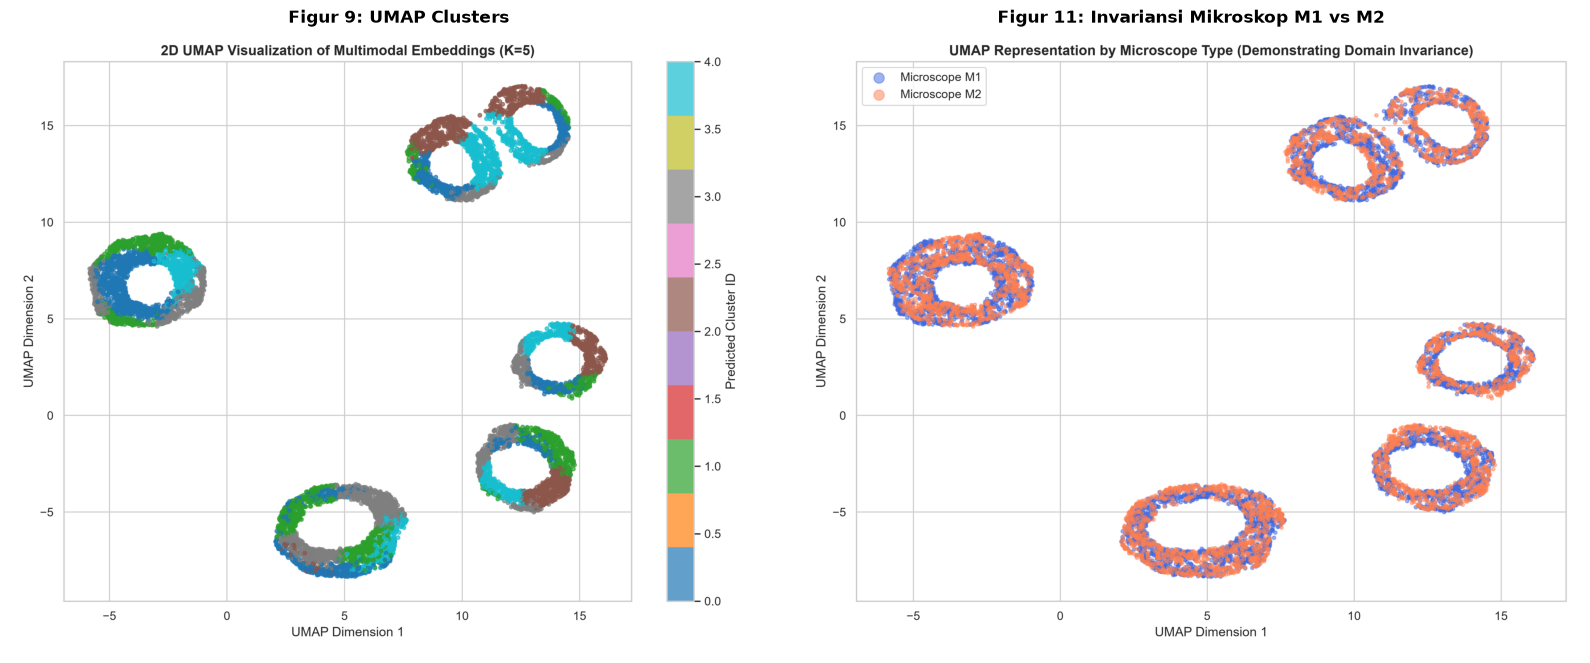

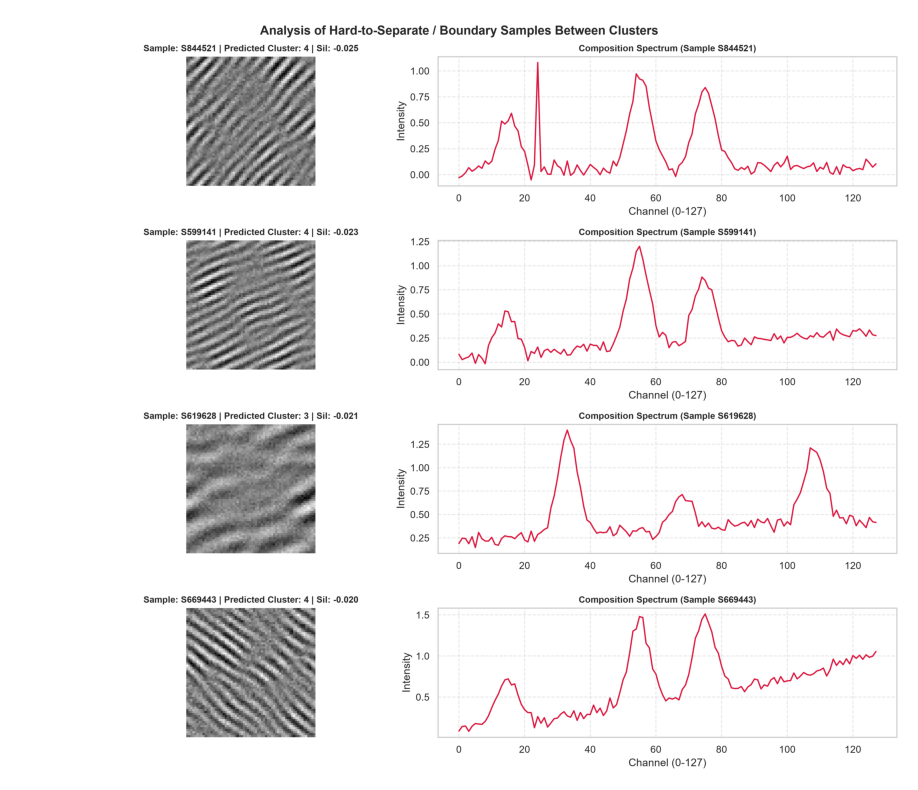

In [8]:
p_comp = 'artifacts/task3/table_cluster_composition.csv' if os.path.exists('artifacts/task3/table_cluster_composition.csv') else '../../artifacts/task3/table_cluster_composition.csv'
comp_df = pd.read_csv(p_comp)
display(comp_df)

p_fig9 = 'artifacts/task3/fig9_umap_clusters.png' if os.path.exists('artifacts/task3/fig9_umap_clusters.png') else '../../artifacts/task3/fig9_umap_clusters.png'
p_fig11 = 'artifacts/task3/fig11_microscope_invariance.png' if os.path.exists('artifacts/task3/fig11_microscope_invariance.png') else '../../artifacts/task3/fig11_microscope_invariance.png'
p_fig12 = 'artifacts/task3/fig12_overlapping_cluster_samples.png' if os.path.exists('artifacts/task3/fig12_overlapping_cluster_samples.png') else '../../artifacts/task3/fig12_overlapping_cluster_samples.png'

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(plt.imread(p_fig9))
axes[0].set_title('Figur 9: UMAP Clusters', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(plt.imread(p_fig11))
axes[1].set_title('Figur 11: Invariansi Mikroskop M1 vs M2', fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 10))
plt.imshow(plt.imread(p_fig12))
plt.axis('off')
plt.show()


## 8. Verifikasi File Prediksi Akhir (`prediksi_cluster.csv`)
> **Penanggung Jawab:** **Zacky Yusup Hakim** (NIM: 101032300183)

Memverifikasi bahwa file output akhir `prediksi_cluster.csv` memenuhi 100% kriteria penilaian ujian UTS Deep Learning:
- Jumlah baris tepat 36.000
- Kolom `id_sampel,cluster`
- Nilai cluster berupa integer (0, 1, 2, 3, 4)
- 0 NaN / missing values

In [9]:
p_csv = 'prediksi_cluster.csv' if os.path.exists('prediksi_cluster.csv') else ('cluster.csv' if os.path.exists('cluster.csv') else ('../../prediksi_cluster.csv' if os.path.exists('../../prediksi_cluster.csv') else '../../cluster.csv'))
cdf = pd.read_csv(p_csv)
print(f'File: {os.path.basename(p_csv)}')
print(f'Total Baris: {len(cdf):,}')
print(f'Header: {list(cdf.columns)}')
print(f'Tipe Kolom Cluster: {cdf["cluster"].dtype}')
print(f'Jumlah NaN: {cdf.isna().sum().sum()}')
print(f'Jumlah id_sampel Unik: {cdf["id_sampel"].nunique():,}')
print('Distribusi Klaster:')
print(cdf['cluster'].value_counts().sort_index())

File: prediksi_cluster.csv
Total Baris: 36,000
Header: ['id_sampel', 'cluster']
Tipe Kolom Cluster: int64
Jumlah NaN: 0
Jumlah id_sampel Unik: 36,000
Distribusi Klaster:
cluster
0    8354
1    6923
2    5433
3    8032
4    7258
Name: count, dtype: int64
